# Compute the potential-field data

Compute the potential-field data produced by the geological source simulated in the notebook `1_model.ipynb`.

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
import time

In [5]:
import pickle

In [6]:
from gravmag import data_structures, utils, aux_vedo, constants, check
from gravmag.models import rectangular_prism as rp

In [7]:
import vedo

In [8]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

In [9]:
# Python package noise (https://github.com/caseman/noise) for generating Perlin noise.
# Such noise is usefull to simulate topography.
import noise

### Load the model

In [10]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [11]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [12]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [13]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [14]:
model_magnetization = pickle.load(open('model/1_model_magnetization.pickle', 'rb'))

In [15]:
check.is_array(x=model_magnetization['intensity'], ndim=1)
Nprisms = model_magnetization['intensity'].size
try:
    check.is_scalar(x=model_magnetization['inclination'], positive=False)
    check.is_scalar(x=model_magnetization['declination'], positive=False)
except:
    check.is_array(x=model_magnetization['inclination'], ndim=1, shape=(Nprisms,))
    check.is_array(x=model_magnetization['declination'], ndim=1, shape=(Nprisms,))

In [16]:
print('Magnetization direction inc = {}° dec = {}°'.format(model_magnetization['inclination'], model_magnetization['declination']))

Magnetization direction inc = -7.0° dec = 19.0°


In [17]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=model_magnetization['inclination'], dec=model_magnetization['declination'])

In [18]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [19]:
# model properties
print("(xmin, xmax) = ({:.3f}, {:.3f}) m".format(model['x1'].min(), model['x2'].max()))
print("(ymin, ymax) = ({:.3f}, {:.3f}) m".format(model['y1'].min(), model['y2'].max()))
print("(top min, top max) = ({:.3f}, {:.3f}) m".format(model['z1'].min(), model['z1'].max()))
print("(bottom min, bottom max) = ({:.3f}, {:.3f}) m".format(model['z2'].min(), model['z2'].max()))
print("number of prisms: {}".format(model['x1'].size))

(xmin, xmax) = (-4337.868, 3802.721) m
(ymin, ymax) = (-2224.008, 4373.346) m
(top min, top max) = (0.000, 353.355) m
(bottom min, bottom max) = (446.646, 800.001) m
number of prisms: 774


In [20]:
# compute the Cartesian components of magnetization
mx, my, mz = utils.magnetization_components(
    np.vstack(
        [
            model_magnetization['intensity'], 
            np.broadcast_to(array=model_magnetization['inclination'], shape=(model_magnetization['intensity'].size,)), 
            np.broadcast_to(array=model_magnetization['declination'], shape=(model_magnetization['intensity'].size,)), 
        ]).T
)

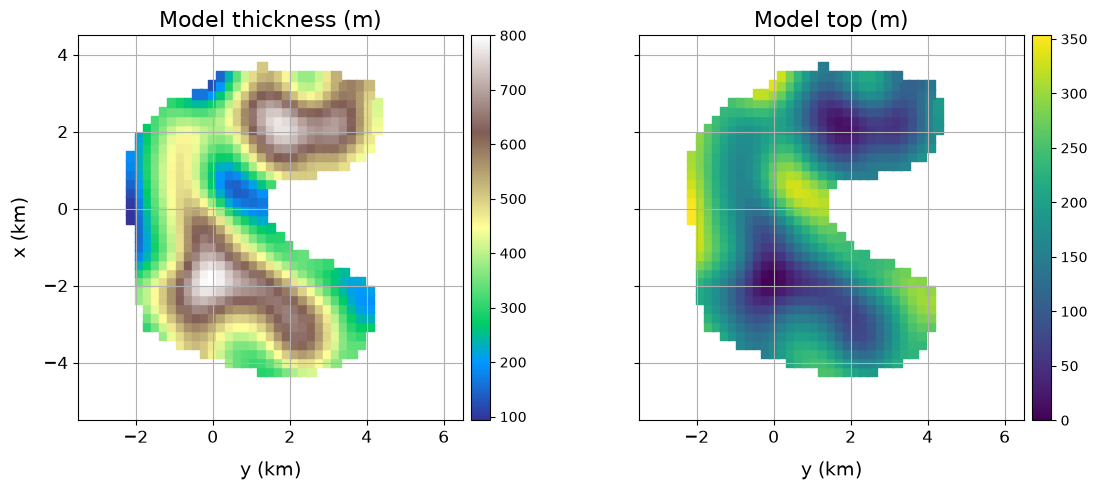

In [21]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, 
    sharex=False, sharey=True,
    figsize=(12, 5), 
)

axs[0].set_title("Model thickness (m)", fontsize=16)
axs[0].axis('scaled')
image = axs[0].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z2']-model['z1'],
    marker='s',
    cmap='terrain'
)
axs[0].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[0].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[0].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[0])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[0].grid()
axs[0].set_ylabel('x (km)', fontsize=14, labelpad=10)
axs[0].set_xlabel('y (km)', fontsize=14, labelpad=10)

axs[1].set_title("Model top (m)", fontsize=16)
axs[1].axis('scaled')
image = axs[1].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z1'],
    marker='s',
    cmap='viridis'
)
axs[1].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[1].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[1].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[1])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[1].grid()
axs[1].set_xlabel('y (km)', fontsize=14, labelpad=10)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.30, hspace=0.05)

plt.tight_layout()

plt.show()

### Main field

In [23]:
main_field = pickle.load(open('test_B/2B_main_field.pickle', 'rb'))

In [24]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [25]:
# compute a normalized horizontal projection of F_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])

### Points were we compute the synthetic data

In [61]:
data_surface_shape = (480,400)

X, Y = data_structures.grid_xy_to_full_matrices_view(
    x=np.linspace(data_area[0], data_area[1], data_surface_shape[0]),
    y=np.linspace(data_area[2], data_area[3], data_surface_shape[1]),
    shape=data_surface_shape
)

# create a variable to store the data surface
data_surface = np.empty(data_surface_shape)

#### Generate a synthetic random surfaces with the Python package [`noise`](https://pypi.org/project/noise/),
# by following the example presented at [Jack McKew's Blog](https://jackmckew.dev/3d-terrain-in-python.html)

# generate the data surface
for i in range(data_surface_shape[0]):
    for j in range(data_surface_shape[1]):
        data_surface[i][j] = 150*noise.pnoise2(
            i/200, 
            j/300, 
            octaves=23, 
            persistence=0.2,
            lacunarity=8, 
            repeatx=3, 
            repeaty=2, 
            base=0
        )

data_surface -= 50.

In [62]:
data_surface[::4,::5].shape

(120, 80)

In [65]:
np.prod(data_surface[::4,::5].shape)

np.int64(9600)

In [68]:
# number of points along x and y
data_shape = data_surface[::4,::5].shape
print('n. data = {}'.format(data_shape[0]*data_shape[1]))

# minimum x, maximum x, minimum y and maximum y
data_area = [-7100, 7500, -4800, 7200]

# grid spacing
data_dx, data_dy = data_structures.grid_xy_spacing(area=data_area, shape=data_shape)
print('dx = {:.3f} m | dy = {:.3f} m'.format(data_dx, data_dy))

n. data = 9600
dx = 122.689 m | dy = 151.899 m


In [69]:
coordinates_metadata = dict()
coordinates_metadata['shape'] = data_shape
coordinates_metadata['area'] = data_area
coordinates_metadata['spacing'] = (data_dx, data_dy)
pickle.dump(coordinates_metadata, open('test_B/2B_coordinates_metadata.pickle', 'wb'))

In [70]:
# initial grid of coordinates at z = 0 m
coordinates = data_structures.grid_xy(
    area=data_area,
    shape=data_shape,
    z0=0
)

coordinates = data_structures.grid_xy_to_full_flatten(
    grid=coordinates,
    grid_orientation='xy'
)

In [71]:
# set the data surface as the 'z' coordinate of 'coordinates'
coordinates['z'] = data_structures.grid_xy_full_matrix_to_flatten(
    grid=data_surface[::4,::5],
    grid_orientation='xy'
)

In [72]:
coordinates['z'].size

9600

In [73]:
print('Data cordinates z \n    minimum: {:>7.2f} \n mean (std): {:>7.2f} ({:>5.2f}) \n    maximum: {:>7.2f}'.format(
        np.min(coordinates['z']), np.mean(coordinates['z']), np.std(coordinates['z']), np.max(coordinates['z'])
    )
)

Data cordinates z 
    minimum: -140.15 
 mean (std):  -53.29 (30.47) 
    maximum:   34.19


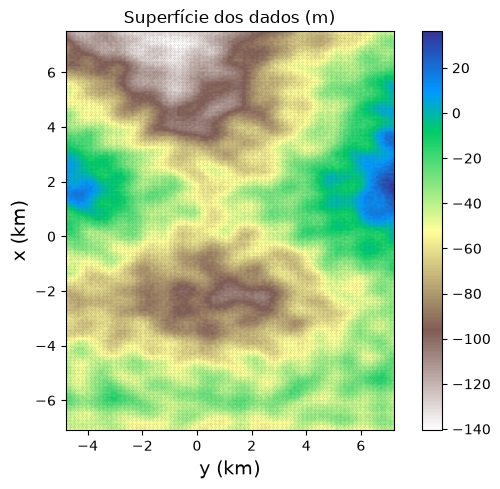

In [74]:
plt.close('all')
plt.figure(figsize=(6,5))

plt.title("Superfície dos dados (m)")
plt.axis('scaled')
plt.pcolor(
    Y*0.001, X*0.001, data_surface, cmap='terrain_r'
)
plt.colorbar()
plt.plot(0.001*coordinates['y'], 0.001*coordinates['x'], lw=0, marker='.', c=3*(0.4,), ms=0.2)
#plf.model_boundaries(model)
plt.ylim(0.001*data_area[0], 0.001*data_area[1])
plt.xlim(0.001*data_area[2], 0.001*data_area[3])
plt.xlabel('y (km)', fontsize=14)
plt.ylabel('x (km)', fontsize=14)

plt.tight_layout()

plt.savefig('test_B/2B_data_surface.png', dpi=300)

plt.show()

In [76]:
coordinates = pickle.load(open('test_B/2B_coordinates.pickle', 'rb'))

In [78]:
print('num. data points = {}'.format(coordinates['x'].size))

num. data points = 9600


### Synthetic data

In [79]:
simulated_fields = dict()

In [80]:
# Run this cell may take some time.

start = time.time()

# Compute the magnetic field components
simulated_fields['bx'] = rp.mag(
    coordinates = coordinates, 
    prisms = model, 
    mx = mx, 
    my = my, 
    mz = mz, 
    field = 'x'
)

simulated_fields['by'] = rp.mag(
    coordinates = coordinates, 
    prisms = model, 
    mx = mx, 
    my = my, 
    mz = mz, 
    field = 'y'
)

simulated_fields['bz'] = rp.mag(
    coordinates = coordinates, 
    prisms = model, 
    mx = mx, 
    my = my, 
    mz = mz, 
    field = 'z'
)

end = time.time()

print('elapsed time = {} s'.format(end - start))

elapsed time = 15.858723878860474 s


In [81]:
simulated_fields['b'] = np.sqrt(simulated_fields['bx']**2 + simulated_fields['by']**2 + simulated_fields['bz']**2)

In [82]:
# Compute the approximated total-field anomaly (Blakely, 1996, p. 179)
simulated_fields['atfa'] = F_hat[0]*simulated_fields['bx'] + F_hat[1]*simulated_fields['by'] + F_hat[2]*simulated_fields['bz']

In [83]:
# Run this cell may take some time.

start = time.time()

# true RTP anomaly
simulated_fields['rtp'] = rp.mag(
    coordinates = coordinates, 
    prisms=model, 
    mx=np.zeros_like(model_magnetization['intensity']), 
    my=np.zeros_like(model_magnetization['intensity']), 
    mz=model_magnetization['intensity'], 
    field='z'
)

end = time.time()

print('elapsed time = {} s'.format(end - start))

elapsed time = 5.363426208496094 s


In [84]:
pickle.dump(simulated_fields, open('test_B/2B_simulated_fields_full.pickle', 'wb'))

In [85]:
simulated_fields = pickle.load(open('test_B/2B_simulated_fields_full.pickle', 'rb'))

In [86]:
# Generate pseudo-random Gaussian noise for total-field anomaly data
rng = np.random.default_rng(126543786908888123)
tfa_noise = rng.normal(loc=0., scale=5, size=simulated_fields['atfa'].size)

In [87]:
# Save data in a txt file
np.savetxt(
    fname="data.txt", 
    X=np.vstack([coordinates['x'], coordinates['y'], coordinates['z'], simulated_fields['atfa'] + tfa_noise]).T,
    header = "X Y Z TFA"
)

# Plot the data

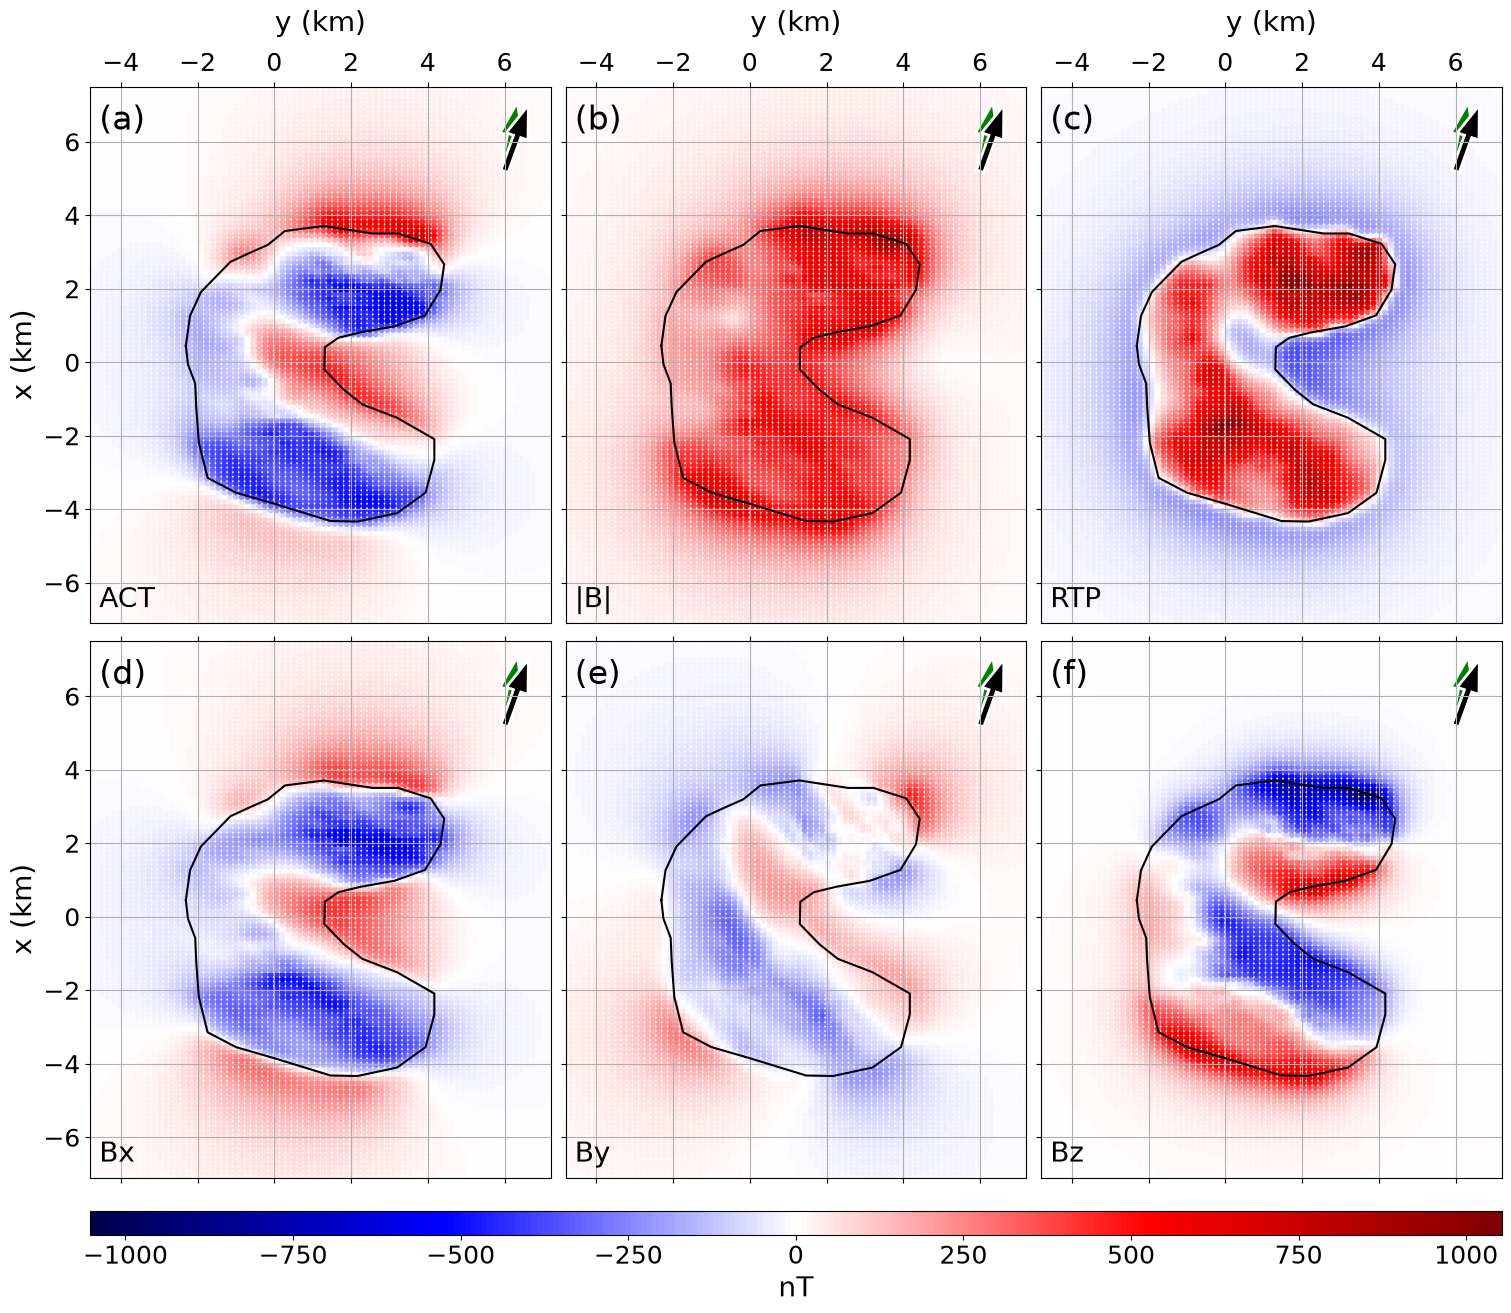

In [89]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,13)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

mosaic_elements = ['a', 'b', 'c', 'd', 'e', 'f']

titles = [
    'ACT', '|B|', 'RTP', 
    'Bx', 'By', 'Bz'
]

units = 6*['nT']

ranges_b = np.max(np.abs(
    [
        simulated_fields['atfa'],
        simulated_fields['b'], 
        simulated_fields['rtp'], 
        simulated_fields['bx'], 
        simulated_fields['by'], 
        simulated_fields['bz'], 
    ]
))

ranges = 6*[ranges_b]

for (element, field, label, ranges_field, unit, title) in zip(
    mosaic_elements, 
    ['atfa', 'b', 'rtp', 'bx', 'by', 'bz'], 
    labels,
    ranges,
    units,
    titles
):
    ax = mosaic[element]
    #ax.axis('scaled')
    im = ax.scatter(
        x=coordinates['y']*0.001, y=coordinates['x']*0.001, 
        c=simulated_fields[field], s=10,
        cmap='seismic', vmin=-ranges_field, vmax=ranges_field
    )
    # ax_divider = make_axes_locatable(ax)
    # cax = ax_divider.append_axes("right", size="3%", pad="2%")
    # cb = fig.colorbar(im, cax=cax)
    # cb.ax.tick_params(labelsize=14)
    # cb.ax.set_xlabel(unit, fontsize=16, loc='left')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*data_area[0], 0.001*data_area[1])
    ax.set_xlim(0.001*data_area[2], 0.001*data_area[3])
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)
    ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=20)
    ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='green', ec='white') 
    ax.arrow(x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='black', ec='white') 

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.10)
    
for element in ['a','d']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
for element in ['d','e', 'f']:
    mosaic[element].tick_params(top=True, bottom=True, labelbottom=False)

cb = fig.colorbar(
    mosaic['c'].collections[0], 
    ax=[mosaic['d'], mosaic['e'], mosaic['f']], 
    location='bottom',
    aspect=60
)
cb.ax.tick_params(labelsize=18)
cb.ax.set_xlabel('nT', fontsize=20, loc='center')
    
plt.savefig('test_B/2B_potential_fields_1.png', dpi=300)

plt.show()